# CSL236 Mid-Term Project: Loan Approval Prediction
### Preprocessing pipeline and baseline model

| | |
|---|---|
| **Course** | CSL236 – Introduction to Artificial Intelligence & Machine Learning |
| **Team number** | [Team No.] |
| **Members (Name – Roll No.)** | 1. [Member 1 name] – [Roll no.] <br> 2. [Member 2 name] – [Roll no.] <br> 3. [Member 3 name] – [Roll no.] <br> 4. [Member 4 name] – [Roll no.] |
| **Dataset** | `loan_approval_dataset.csv` (4,269 loan applications, 13 columns) |

**Problem statement.** A bank receives loan applications and has to decide which ones to approve. Each row has an applicant's
education, employment type, income, requested loan amount and term, CIBIL credit score and declared assets, plus the
final decision (`loan_status`: *Approved* / *Rejected*). We predict `loan_status` from the other columns. This is a
**binary classification** problem. A model like this lets a bank screen applications quickly and consistently, and
shows which factors actually drive the decision.

**Focus of this notebook.** The guidelines mark the *process*, not the accuracy. So every stage (A–H) below has
code, output, and a markdown cell explaining **why** we made each choice. Where a technique does not apply, we say so and explain why.

> **Leakage rule we follow:** the data is split into train and test sets right after Stage A. Every imputer, encoder,
> bin edge, scaler, feature selector and PCA below is **fitted on the training set only** and then applied to the test set.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, MinMaxScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

RANDOM_STATE = 42                                   # fixed seed so results are reproducible
pd.set_option('display.float_format', '{:,.2f}'.format)
pd.set_option('display.max_columns', 30)

# Chart style: one colour per class, used consistently in every chart
APPROVED_C, REJECTED_C, NEUTRAL_C = '#2a78d6', '#eb6834', '#8a8983'
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'axes.titleweight': 'bold',
                     'axes.titlesize': 11, 'axes.labelsize': 10})

---
## Stage A: Understanding the data
We load the CSV and look at its shape, the data type of every column, summary statistics and missing values.
Then we separate the numerical columns from the categorical ones.

In [2]:
df = pd.read_csv('loan_approval_dataset.csv')
print('Raw column names:', df.columns.tolist()[:4], '...')
print('Raw value example :', repr(df.iloc[0, 2]))

Raw column names: ['loan_id', ' no_of_dependents', ' education', ' self_employed'] ...
Raw value example : ' Graduate'


**Observation:** every column name and every text value starts with a space (`' education'`, `' Graduate'`).
If we left it, `df['education']` would raise a `KeyError` and `== 'Graduate'` would never match. So we strip the
whitespace first. This is plain text cleaning with nothing learned from the data, so it is safe before the split.

In [3]:
df.columns = df.columns.str.strip()
text_cols = df.select_dtypes(exclude='number').columns
for col in text_cols:
    df[col] = df[col].str.strip()

print('Shape (rows, columns):', df.shape)
df.head()

Shape (rows, columns): (4269, 13)


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [4]:
# Data type of every column
dtypes = pd.DataFrame({'dtype': df.dtypes.astype(str), 'unique_values': df.nunique()})
dtypes

,dtype,unique_values
loan_id,int64,4269
no_of_dependents,int64,6
education,str,2
self_employed,str,2
income_annum,int64,98
loan_amount,int64,378
loan_term,int64,10
cibil_score,int64,601
residential_assets_value,int64,278
commercial_assets_value,int64,188


In [5]:
# Summary statistics of the numerical columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
loan_id,"4,269.00","2,135.00","1,232.50",1.00,"1,068.00","2,135.00","3,202.00","4,269.00"
no_of_dependents,"4,269.00",2.50,1.70,0.00,1.00,3.00,4.00,5.00
income_annum,"4,269.00","5,059,123.92","2,806,839.83","200,000.00","2,700,000.00","5,100,000.00","7,500,000.00","9,900,000.00"
loan_amount,"4,269.00","15,133,450.46","9,043,362.98","300,000.00","7,700,000.00","14,500,000.00","21,500,000.00","39,500,000.00"
loan_term,"4,269.00",10.90,5.71,2.00,6.00,10.00,16.00,20.00
cibil_score,"4,269.00",599.94,172.43,300.00,453.00,600.00,748.00,900.00
residential_assets_value,"4,269.00","7,472,616.54","6,503,636.59","-100,000.00","2,200,000.00","5,600,000.00","11,300,000.00","29,100,000.00"
commercial_assets_value,"4,269.00","4,973,155.31","4,388,966.09",0.00,"1,300,000.00","3,700,000.00","7,600,000.00","19,400,000.00"
luxury_assets_value,"4,269.00","15,126,305.93","9,103,753.67","300,000.00","7,500,000.00","14,600,000.00","21,700,000.00","39,200,000.00"
bank_asset_value,"4,269.00","4,976,692.43","3,250,185.31",0.00,"2,300,000.00","4,600,000.00","7,100,000.00","14,700,000.00"


In [6]:
# Summary of the text columns
df.describe(exclude='number').T

,count,unique,top,freq
education,4269,2,Graduate,2144
self_employed,4269,2,Yes,2150
loan_status,4269,2,Approved,2656


In [7]:
# Missing values: count and percentage per column
missing = pd.DataFrame({'missing_count': df.isna().sum(),
                        'missing_pct': (df.isna().mean() * 100).round(2)})
missing

,missing_count,missing_pct
loan_id,0,0.00
no_of_dependents,0,0.00
education,0,0.00
self_employed,0,0.00
income_annum,0,0.00
loan_amount,0,0.00
loan_term,0,0.00
cibil_score,0,0.00
residential_assets_value,0,0.00
commercial_assets_value,0,0.00


In [8]:
# Separate numerical and categorical columns
id_col, target = 'loan_id', 'loan_status'
num_cols = [c for c in df.select_dtypes(include='number').columns if c != id_col]
cat_cols = [c for c in df.select_dtypes(exclude='number').columns if c != target]

print('Identifier column :', id_col)
print('Target column     :', target)
print(f'Numerical ({len(num_cols)})    :', num_cols)
print(f'Categorical ({len(cat_cols)})  :', cat_cols)
print('Duplicate rows (ignoring loan_id):', df.drop(columns=id_col).duplicated().sum())

Identifier column : loan_id
Target column     : loan_status
Numerical (9)    : ['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']
Categorical (2)  : ['education', 'self_employed']
Duplicate rows (ignoring loan_id): 0


In [9]:
for col in cat_cols + [target]:
    print(df[col].value_counts().to_string(), '\n')

education
Graduate        2144
Not Graduate    2125 

self_employed
Yes    2150
No     2119 

loan_status
Approved    2656
Rejected    1613 



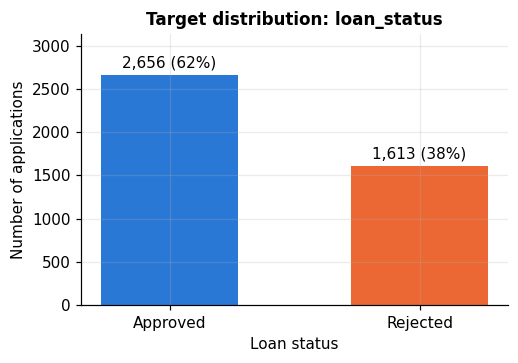

In [10]:
counts = df[target].value_counts()
fig, ax = plt.subplots(figsize=(5, 3.2))
bars = ax.bar(counts.index, counts.values, color=[APPROVED_C, REJECTED_C], width=0.55)
ax.bar_label(bars, labels=[f'{v:,} ({v/len(df):.0%})' for v in counts.values], padding=3)
ax.set_title('Target distribution: loan_status')
ax.set_xlabel('Loan status'); ax.set_ylabel('Number of applications')
ax.set_ylim(0, counts.max() * 1.18)
plt.show()

**What Stage A tells us**

* **4,269 rows × 13 columns.** `loan_id` is only a row number, so it has no predictive meaning and we drop it.
  `loan_status` is the target, which leaves **11 input features**.
* **Numerical (9):** `no_of_dependents`, `income_annum`, `loan_amount`, `loan_term`, `cibil_score` and four asset values.
  `no_of_dependents` (0–5) and `loan_term` (2–20 years, even numbers only) are *discrete* numbers. The rest are continuous amounts in rupees.
* **Categorical (2 + target):** `education`, `self_employed`, and the target `loan_status`. All three have exactly two values.
* **No `NaN` cells** and no duplicate rows. But an empty-cell count is not the whole story. Next we check whether the values make sense.
* **Classes are imbalanced 62 : 38** (Approved : Rejected). So we will use a **stratified** split and report F1 as well as accuracy.

In [11]:
# Sanity check: money amounts, scores and counts can never be negative
negatives = (df[num_cols] < 0).sum()
print(negatives[negatives > 0])
print('\nDistinct negative values:', df.loc[df['residential_assets_value'] < 0, 'residential_assets_value'].unique())

residential_assets_value    28
dtype: int64

Distinct negative values: [-100000]


**Hidden missing values.** `residential_assets_value` has **28 rows with the value −100,000**. The value of a house cannot be
negative, and the fact that every one of them is exactly −100,000 suggests a placeholder code for "unknown", not a real
measurement. We treat these 28 values as **missing** in Stage B.
(Note: `commercial_assets_value` has zeros. Zero is valid: the applicant simply owns no commercial property, so we keep those.)

---
## Train/test split (before any preprocessing is fitted)
We split **now**, before fitting any imputer, encoder, bin edge or scaler. If we computed, say, the median or the scaler's mean on all
4,269 rows, test-set information would leak into training and our test score would be over-optimistic.

* **80 % train / 20 % test**, `stratify=y` so both sets keep the 62 : 38 class ratio, `random_state=42` for reproducibility.
* `loan_id` is dropped here because it is an identifier, not a feature.

In [12]:
X = df.drop(columns=[id_col, target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_train, X_test = X_train.copy(), X_test.copy()

print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Approved share -> train: {:.3f} | test: {:.3f}'.format(
    (y_train == 'Approved').mean(), (y_test == 'Approved').mean()))
n_features_start = X_train.shape[1]
print('Features at the start:', n_features_start)

Train: (3415, 11)  Test: (854, 11)
Approved share -> train: 0.622 | test: 0.622
Features at the start: 11


---
## Stage B: Handling missing values
**Step 1: make the hidden missing values explicit.** We replace the impossible negative values with `NaN`.
This is a fixed rule ("a negative asset value is invalid"). It learns nothing from the data, so we can apply it to train and test separately.

In [13]:
col = 'residential_assets_value'
for part in (X_train, X_test):
    part[col] = part[col].mask(part[col] < 0)      # negative -> NaN (column becomes float)

missing_b = pd.DataFrame({'train_missing': X_train.isna().sum(), 'test_missing': X_test.isna().sum()})
missing_b['train_pct'] = (missing_b['train_missing'] / len(X_train) * 100).round(2)
missing_b[missing_b.sum(axis=1) > 0]

,train_missing,test_missing,train_pct
residential_assets_value,27,1,0.79


In [14]:
print(f"Train mean  : {X_train[col].mean():>14,.0f}")
print(f"Train median: {X_train[col].median():>14,.0f}")
print(f"Skewness    : {X_train[col].skew():>14.2f}")

Train mean  :      7,476,476
Train median:      5,700,000
Skewness    :           0.99


**Step 2: impute or drop? Decision per column**

| Column | Missing | Decision | Reason |
|---|---|---|---|
| `residential_assets_value` | 28 rows overall, 0.66 % (27 train, 1 test) | **Impute with the median** | Few rows are affected, but dropping them would throw away otherwise valid applications. More importantly, a deployed model cannot "drop" a new applicant with this value missing, so it needs a rule to fill it. The column is **right-skewed** (mean > median, skew ≈ 1), so the median is a more typical value than the mean, which rich applicants pull upwards. |
| All other 10 feature columns | 0 | No action | Nothing to fill. |

*Alternatives we considered:* dropping the rows (acceptable at 0.66 %, but it gives no rule for new applicants); a
**group-wise median** (for example, the median within each income band), which is slightly more precise but adds complexity for 28 values.
The median is learned **from the training set only** and reused on the test set.

In [15]:
imputer = SimpleImputer(strategy='median')
imputer.fit(X_train[[col]])                       # learn the median from TRAIN only
print('Median learned from train:', f'{imputer.statistics_[0]:,.0f}')

X_train[[col]] = imputer.transform(X_train[[col]])
X_test[[col]]  = imputer.transform(X_test[[col]])
print('Missing values left -> train:', X_train.isna().sum().sum(), '| test:', X_test.isna().sum().sum())

Median learned from train: 5,700,000
Missing values left -> train: 0 | test: 0


---
## Stage C: Encoding categorical data
Machine-learning models need numbers, so every text column must be converted. The right scheme depends on the column type:

| Column | Values | Type | Encoding | Why |
|---|---|---|---|---|
| `education` | Not Graduate, Graduate | Binary **and ordinal** (a degree is a higher level of education) | Ordinal: **Not Graduate = 0 < Graduate = 1** | The categories have a natural order, so we state it explicitly instead of letting a tool pick alphabetical order. |
| `self_employed` | No, Yes | Binary, no order | 0/1 mapping: **No = 0, Yes = 1** | Two values only. A single 0/1 column carries all the information. |
| `loan_status` (target) | Rejected, Approved | Binary target | **Rejected = 0, Approved = 1** | Approved is the "positive" class we want to predict. |

**Nominal columns (one-hot encoding):** this dataset has **no multi-category nominal column**, so one-hot encoding is **not
needed**. If it had one (for example `loan_purpose` = home / car / education), we would one-hot encode it, because giving
unordered categories the numbers 0, 1, 2 would invent a false order. We deliberately do **not** one-hot the binary columns:
that would create two columns that always sum to 1 (perfectly collinear) and add no information.

The bins created in Stage D are also ordinal, and we encode them with an explicitly stated order there.

In [16]:
# education: ordinal encoder with the order written out explicitly (fitted on train only)
edu_encoder = OrdinalEncoder(categories=[['Not Graduate', 'Graduate']])
edu_encoder.fit(X_train[['education']])
X_train['education'] = edu_encoder.transform(X_train[['education']]).ravel().astype(int)
X_test['education']  = edu_encoder.transform(X_test[['education']]).ravel().astype(int)

# self_employed: binary 0/1 mapping
self_emp_map = {'No': 0, 'Yes': 1}
X_train['self_employed'] = X_train['self_employed'].map(self_emp_map)
X_test['self_employed']  = X_test['self_employed'].map(self_emp_map)

# target: Rejected = 0, Approved = 1
target_map = {'Rejected': 0, 'Approved': 1}
y_train, y_test = y_train.map(target_map), y_test.map(target_map)

assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0, 'unmapped category!'
print('Encoded education order:', dict(zip(edu_encoder.categories_[0], range(2))))
print('Non-numeric columns left:', X_train.select_dtypes(exclude='number').columns.tolist())
X_train[['education', 'self_employed']].head()

Encoded education order: {'Not Graduate': 0, 'Graduate': 1}
Non-numeric columns left: []


,education,self_employed
1224,1,1
478,0,1
3065,0,0
326,0,1
2991,0,0


---
## Stage D: Binning / discretization
Binning turns a continuous column into ranges. It helps when **the ranges carry the meaning** rather than the exact value,
for example when a bank applies a cut-off. We look at the data (training set only) before deciding.

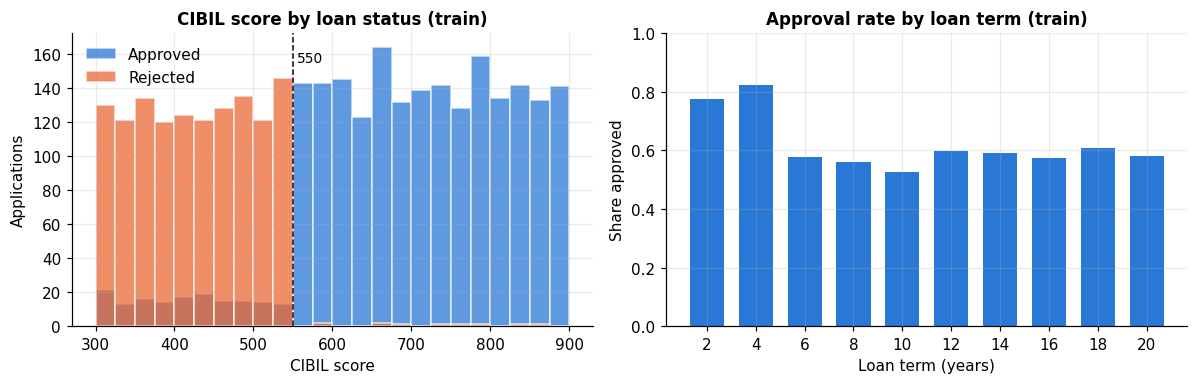

In [17]:
train_view = X_train.assign(loan_status=y_train.map({1: 'Approved', 0: 'Rejected'}))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

bins = np.arange(300, 925, 25)
for label, colr in [('Approved', APPROVED_C), ('Rejected', REJECTED_C)]:
    axes[0].hist(train_view.loc[train_view.loan_status == label, 'cibil_score'], bins=bins,
                 color=colr, alpha=0.75, label=label, edgecolor='white', linewidth=1)
axes[0].axvline(550, color='#0b0b0b', linestyle='--', linewidth=1)
axes[0].text(555, axes[0].get_ylim()[1] * 0.9, '550', fontsize=9)
axes[0].set_title('CIBIL score by loan status (train)')
axes[0].set_xlabel('CIBIL score'); axes[0].set_ylabel('Applications'); axes[0].legend(frameon=False)

rate = train_view.groupby('loan_term')['loan_status'].apply(lambda s: (s == 'Approved').mean())
axes[1].bar(rate.index, rate.values, width=1.4, color=APPROVED_C)
axes[1].set_title('Approval rate by loan term (train)')
axes[1].set_xlabel('Loan term (years)'); axes[1].set_ylabel('Share approved')
axes[1].set_ylim(0, 1); axes[1].set_xticks(rate.index)
plt.tight_layout(); plt.show()

**Which columns do we bin, and how?**

1. **`cibil_score` → `cibil_band` (domain-defined bins).** CIBIL scores run from 300 to 900 and are commonly read in standard
   bands. We use **Poor 300–549, Fair 550–649, Good 650–749, Excellent 750–900**. The chart shows why this is justified: about
   9 in 10 applications below **550** are rejected, while almost every one above it is approved. So the *band* an applicant falls in carries the decision.
2. **`loan_term` → `term_band` (domain-defined bins).** In lending, a loan up to 5 years is short-term, 6–10 years medium and above 10 years long-term.
   The chart supports a short-term group: 2- and 4-year loans are approved noticeably more often.
3. **`income_annum` → `income_band` (equal-frequency bins, 4 quartiles).** Income has no standard bands, so we let the data
   choose: each bin holds 25 % of *training* applicants. We chose equal-frequency over equal-width so that no bin is almost empty.
   The quartile edges are **learned from the training set** and reused on the test set.

**Not binned:** `no_of_dependents` is already a small whole-number count (0–5), so binning would add nothing. The asset and loan amounts
have no meaningful cut-offs, and binning them would only throw away detail.

We **keep the original columns** next to the new bins. Stage G then decides, based on evidence, which version of each is more useful.

In [18]:
# 1) CIBIL: domain-defined bands. right=False -> [300,550), [550,650), [650,750), [750,901)
cibil_edges  = [300, 550, 650, 750, 901]
cibil_labels = ['Poor', 'Fair', 'Good', 'Excellent']
cibil_order  = {'Poor': 0, 'Fair': 1, 'Good': 2, 'Excellent': 3}     # ordinal order, stated explicitly

# 2) Loan term: domain-defined bands. (0,5] short, (5,10] medium, (10,30] long
term_edges  = [0, 5, 10, 30]
term_labels = ['Short', 'Medium', 'Long']
term_order  = {'Short': 0, 'Medium': 1, 'Long': 2}

# 3) Income: equal-frequency quartile edges learned from TRAIN only
inner_edges  = np.quantile(X_train['income_annum'], [0.25, 0.50, 0.75])
income_edges = np.concatenate(([-np.inf], inner_edges, [np.inf]))
print('Income quartile edges learned from train:', [f'{e:,.0f}' for e in inner_edges])

def add_bins(part):
    part['cibil_band']  = pd.cut(part['cibil_score'], cibil_edges, right=False,
                                 labels=cibil_labels).map(cibil_order).astype(int)
    part['term_band']   = pd.cut(part['loan_term'], term_edges,
                                 labels=term_labels).map(term_order).astype(int)
    part['income_band'] = pd.cut(part['income_annum'], income_edges, labels=False).astype(int)
    return part

X_train, X_test = add_bins(X_train), add_bins(X_test)

Income quartile edges learned from train: ['2,600,000', '5,000,000', '7,500,000']


In [19]:
# Does each binned feature separate the classes? (approval rate per bin, training set)
summary = []
for b, names in [('cibil_band', cibil_labels), ('term_band', term_labels), ('income_band', ['Q1', 'Q2', 'Q3', 'Q4'])]:
    g = y_train.groupby(X_train[b]).agg(['count', 'mean'])
    for code, row in g.iterrows():
        summary.append({'feature': b, 'bin': f'{code} = {names[code]}', 'applicants': int(row['count']),
                        'approval_rate': round(row['mean'], 3)})
pd.DataFrame(summary)

,feature,bin,applicants,approval_rate
0,cibil_band,0 = Poor,1437,0.11
1,cibil_band,1 = Fair,556,1.00
2,cibil_band,2 = Good,581,0.99
3,cibil_band,3 = Excellent,841,0.99
4,term_band,0 = Short,695,0.80
5,term_band,1 = Medium,1044,0.56
6,term_band,2 = Long,1676,0.59
7,income_band,0 = Q1,859,0.63
8,income_band,1 = Q2,851,0.61
9,income_band,2 = Q3,883,0.63


**Reading the table:** `cibil_band` separates the classes very sharply (roughly 10 % approval for Poor against about 99 % for every
higher band). `term_band` shows a clear short-term effect. `income_band` is almost flat, since income on its own barely changes the
approval rate. That makes `income_band` a likely candidate for removal in Stage G.

---
### Derived features (domain knowledge)
Before scaling, we add two ratio features that a loan officer would naturally look at. Each is computed row by row, so nothing is learned from other rows and there is no leakage.
* `loan_to_income` = loan_amount / income_annum: how large the loan is relative to earnings.
* `total_assets` = the sum of the four asset values: total collateral the applicant can offer.

In [20]:
asset_cols = ['residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']
for part in (X_train, X_test):
    part['loan_to_income'] = part['loan_amount'] / part['income_annum']
    part['total_assets']   = part[asset_cols].sum(axis=1)

print('Feature count after binning + derived features:', X_train.shape[1])
X_train_raw = X_train.copy()        # snapshot before any transformation (used in Stage F)

Feature count after binning + derived features: 16


---
## Stage E: Scaling and transformation
**1. Transforming skewed columns.** We measure skewness on the training set. A common rule of thumb is that |skew| > 0.75
counts as noticeably skewed. A long right tail lets a few very large values dominate a linear model, so we transform those columns.
The textbook choice is a **log transform**, but these asset columns contain **zeros** (applicants who own no such asset). So before choosing,
we compare `log1p` (log(1 + x)) with the **square root** on the training data. Both are fixed formulas with no learned parameters, so applying them
to train and test separately causes no leakage.

In [21]:
cont_cols = ['income_annum', 'loan_amount', 'cibil_score', 'residential_assets_value',
             'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value',
             'loan_to_income', 'total_assets']
skew_before = X_train[cont_cols].skew().sort_values(ascending=False)
skewed_cols = skew_before[skew_before.abs() > 0.75].index.tolist()
print(skew_before.round(2).to_string())
print('\nColumns needing a transform (|skew| > 0.75):', skewed_cols)

residential_assets_value    1.00
commercial_assets_value     0.96
bank_asset_value            0.58
luxury_assets_value         0.34
loan_amount                 0.32
total_assets                0.31
cibil_score                 0.01
income_annum                0.00
loan_to_income             -0.01

Columns needing a transform (|skew| > 0.75): ['residential_assets_value', 'commercial_assets_value']


In [22]:
# Compare candidate transforms on the TRAINING data
comparison = pd.DataFrame({
    'skew_raw':   X_train[skewed_cols].skew(),
    'skew_log1p': np.log1p(X_train[skewed_cols]).skew(),
    'skew_sqrt':  np.sqrt(X_train[skewed_cols]).skew(),
    'zeros_in_train': (X_train[skewed_cols] == 0).sum()})
comparison.round(2)

,skew_raw,skew_log1p,skew_sqrt,zeros_in_train
residential_assets_value,1.00,-4.93,0.18,39
commercial_assets_value,0.96,-4.35,0.14,81


**Decision: square root, not log.** `log1p` over-corrects. Most assets are in the millions, so log(1 + x) lands around 14–17,
but log(1 + 0) = 0. The handful of zero-asset applicants become extreme values far to the *left*, and the skew flips from about +1 to about −4.6
(worse than doing nothing). The square root is a milder transform: √0 = 0 sits naturally at the start of the range, and the skew
drops to about 0.15, which is close to symmetric. So we apply **`np.sqrt`** to `residential_assets_value` and `commercial_assets_value`.
`bank_asset_value` (skew ≈ 0.58) is below our threshold, so we leave it as it is.

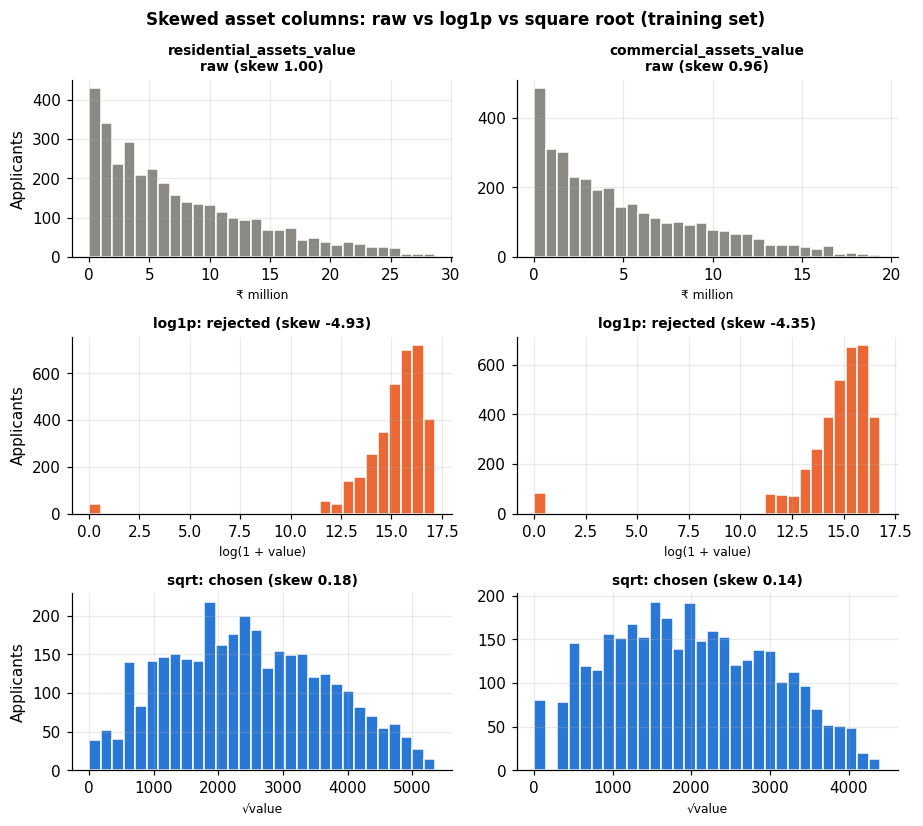

In [23]:
for part in (X_train, X_test):
    part[skewed_cols] = np.sqrt(part[skewed_cols])

fig, axes = plt.subplots(3, len(skewed_cols), figsize=(4.2 * len(skewed_cols), 7.6))
for i, c in enumerate(skewed_cols):
    raw = X_train_raw[c]
    panels = [(raw / 1e6, NEUTRAL_C, f'{c}\nraw (skew {raw.skew():.2f})', '₹ million'),
              (np.log1p(raw), REJECTED_C, f'log1p: rejected (skew {np.log1p(raw).skew():.2f})', 'log(1 + value)'),
              (X_train[c], APPROVED_C, f'sqrt: chosen (skew {X_train[c].skew():.2f})', '√value')]
    for r, (vals, colr, title, xl) in enumerate(panels):
        axes[r, i].hist(vals, bins=30, color=colr, edgecolor='white', linewidth=1)
        axes[r, i].set_title(title, fontsize=9); axes[r, i].set_xlabel(xl, fontsize=8)
        axes[r, 0].set_ylabel('Applicants')
fig.suptitle('Skewed asset columns: raw vs log1p vs square root (training set)', fontweight='bold', fontsize=11)
plt.tight_layout(); plt.show()

**2. Standardisation.** Our baseline model is **Logistic Regression**, and PCA is used in Stage G. Both are sensitive to scale.
Income is in the millions while `cibil_band` is 0–3. Without scaling, the regularisation penalty in logistic regression and the
variance-based components in PCA would be dominated by the large-unit columns. We use **`StandardScaler`** (mean 0, std 1)
rather than Min-Max because Min-Max is set by the single largest value, which makes it sensitive to the outliers kept in Stage F.

The scaler is **fitted on the training set only**. The test set is transformed with the training mean and standard deviation.
(A decision tree would not need scaling, since it only compares values against thresholds. We scale anyway because we compare several models.)

In [24]:
scaler = StandardScaler()
scaler.fit(X_train)                                            # learn mean / std from TRAIN only
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_s  = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns,  index=X_test.index)

check = pd.DataFrame({'train_mean': X_train_s.mean(), 'train_std': X_train_s.std(),
                      'test_mean': X_test_s.mean(), 'test_std': X_test_s.std()})
check.round(3).head(8)

,train_mean,train_std,test_mean,test_std
no_of_dependents,0.00,1.00,0.05,0.98
education,0.00,1.00,-0.00,1.00
self_employed,0.00,1.00,0.03,1.00
income_annum,-0.00,1.00,0.03,1.01
loan_amount,0.00,1.00,0.05,1.02
loan_term,-0.00,1.00,0.03,0.99
cibil_score,-0.00,1.00,0.05,0.99
residential_assets_value,0.00,1.00,0.03,1.03


The training columns now have mean 0 and std 1. The test columns are *close to* 0 and 1 but not exact, and that is expected:
they were scaled with the training statistics, just as a new applicant would be.

---
## Stage F: Outlier treatment
We detect outliers with the **IQR rule** on the raw training values: a value is an outlier if it is below Q1 − 1.5·IQR or above Q3 + 1.5·IQR.

In [25]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((s < lo) | (s > hi)).sum(), lo, hi

rows = []
for c in cont_cols:
    n_raw, lo, hi = iqr_outliers(X_train_raw[c])
    n_after = iqr_outliers(X_train[c])[0]
    rows.append({'column': c, 'lower_fence': lo, 'upper_fence': hi, 'max_value': X_train_raw[c].max(),
                 'outliers_raw': n_raw, 'outliers_after_E': n_after})
outlier_table = pd.DataFrame(rows).set_index('column')
outlier_table

,lower_fence,upper_fence,max_value,outliers_raw,outliers_after_E
column,,,,,
income_annum,"-4,750,000.00","14,850,000.00","9,900,000.00",0,0
loan_amount,"-12,850,000.00","41,950,000.00","39,500,000.00",0,0
cibil_score,7.00,"1,191.00",900.00,0,0
residential_assets_value,"-11,050,000.00","24,550,000.00","28,700,000.00",51,0
commercial_assets_value,"-7,900,000.00","16,900,000.00","19,400,000.00",30,0
luxury_assets_value,"-14,050,000.00","43,150,000.00","39,200,000.00",0,0
bank_asset_value,"-4,900,000.00","14,300,000.00","14,700,000.00",4,4
loan_to_income,0.97,4.99,4.00,0,0
total_assets,"-29,200,000.00","92,400,000.00","87,100,000.00",0,0


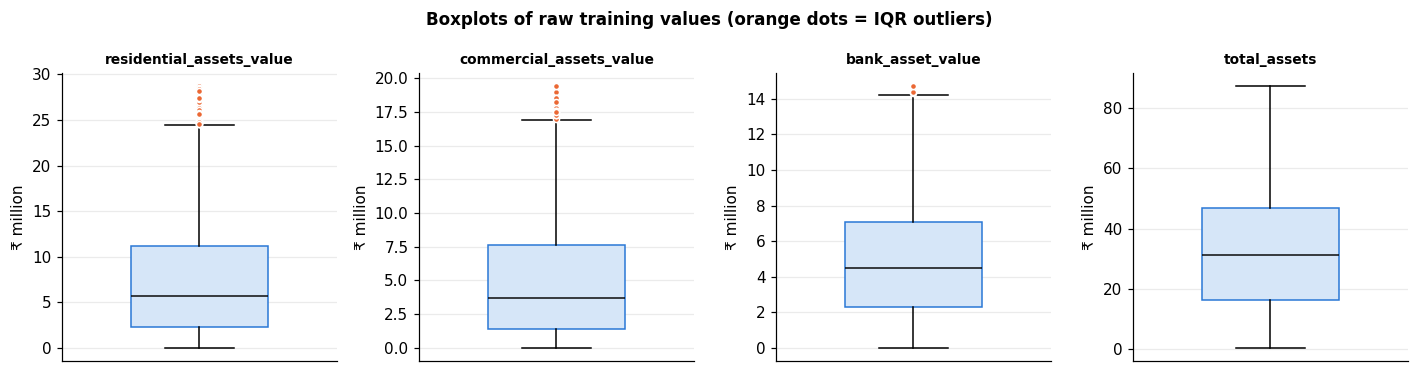

In [26]:
box_cols = ['residential_assets_value', 'commercial_assets_value', 'bank_asset_value', 'total_assets']
fig, axes = plt.subplots(1, len(box_cols), figsize=(13, 3.4))
for ax, c in zip(axes, box_cols):
    ax.boxplot(X_train_raw[c] / 1e6, widths=0.5, patch_artist=True,
               boxprops=dict(facecolor='#d6e6f8', color=APPROVED_C), medianprops=dict(color='#0b0b0b'),
               flierprops=dict(marker='o', markersize=4, markerfacecolor=REJECTED_C, markeredgecolor='white'))
    ax.set_title(c, fontsize=9); ax.set_ylabel('₹ million'); ax.set_xticks([])
fig.suptitle('Boxplots of raw training values (orange dots = IQR outliers)', fontweight='bold', fontsize=11)
plt.tight_layout(); plt.show()

In [27]:
# Are the outliers "real" people? Look at the most extreme residential-asset rows
top = X_train_raw.sort_values('residential_assets_value', ascending=False).head(5)
top[['income_annum', 'loan_amount', 'residential_assets_value', 'luxury_assets_value', 'total_assets']]

,income_annum,loan_amount,residential_assets_value,luxury_assets_value,total_assets
905,9700000,37000000,"28,700,000.00",22800000,"75,000,000.00"
1591,9500000,23000000,"28,500,000.00",21700000,"70,800,000.00"
2318,9600000,29800000,"28,500,000.00",31800000,"74,000,000.00"
1965,9900000,22300000,"28,400,000.00",23600000,"65,800,000.00"
714,9900000,22700000,"28,300,000.00",29700000,"73,300,000.00"


**Genuine value or error? Decision per column**

* **The negative −100,000 values** in `residential_assets_value` were **errors**. They were already treated as missing and imputed in Stage B.
* **The high values flagged by IQR** (51 in `residential_assets_value`, 30 in `commercial_assets_value`, 4 in `bank_asset_value`) are **genuine**.
  They belong to high-income applicants whose other asset columns are also high (see the table above). They stay within realistic ranges
  (at most about ₹29 million of residential property), and they are exactly the wealthy applicants a bank does see. Deleting them would teach the
  model that such people do not exist, and it would then handle them badly at prediction time.
* **Treatment: keep them, and reduce their influence instead of deleting them.** The square-root transform in Stage E pulls in the long
  tail. The `outliers_after_E` column shows that the transformed columns have **no IQR outliers left**. So no capping (winsorising) is needed, and no real applicant was deleted.
  The 4 in `bank_asset_value` (max ₹14.7 M against a fence of ₹14.3 M) sit only just above the fence, so we leave them as they are.
  (With `log1p` the count would have *risen* instead, because the zero-asset applicants become extreme low values. That is one more reason we chose the square root.)

---
## Stage G: Dimensionality reduction
We now have **16 features** (11 original + 3 bins + 2 derived). We reduce them in three filter steps (feature *selection*) and, for
comparison, also try PCA (feature *extraction*). Every step is fitted on the training set only.

In [28]:
n_features_before_G = X_train_s.shape[1]
print('Features before Stage G:', n_features_before_G)

# G1. Variance threshold: remove (near-)constant features.
# Variance depends on units, so we compare variances after Min-Max scaling to [0, 1] (fitted on train).
mm = MinMaxScaler().fit(X_train)
vt = VarianceThreshold(threshold=0.01).fit(mm.transform(X_train))
variances = pd.Series(vt.variances_, index=X_train.columns).sort_values()
low_var = variances[variances < 0.01].index.tolist()
print('Lowest variances (0-1 scale):'); print(variances.head(4).round(4).to_string())
print('Removed by variance threshold:', low_var if low_var else 'none')
features = [c for c in X_train_s.columns if c not in low_var]

Features before Stage G: 16
Lowest variances (0-1 scale):
bank_asset_value           0.05
total_assets               0.05
residential_assets_value   0.05
loan_amount                0.05
Removed by variance threshold: none


**G1 result:** no feature is near-constant. Even the binary columns are split roughly 50/50, which gives variance ≈ 0.25. So the variance filter
removes nothing. We report that honestly rather than forcing a removal.

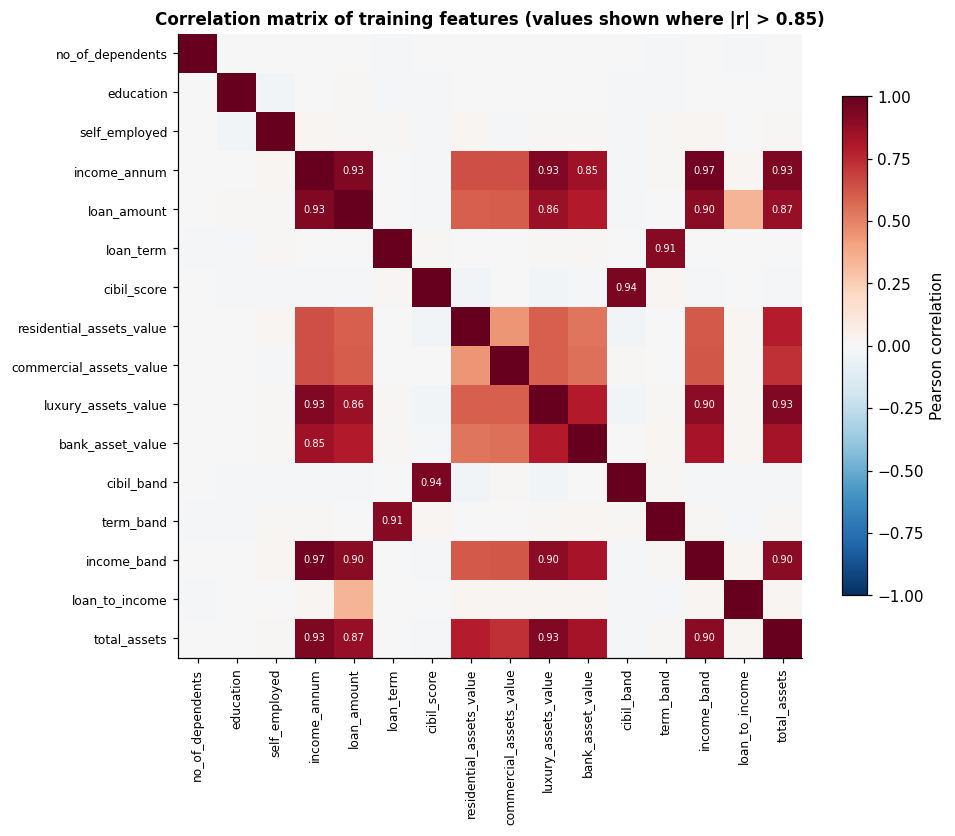

In [29]:
# G2. Correlation filter: among highly correlated pairs (|r| > 0.85) keep the one more related to the target
corr = X_train_s[features].corr()
target_corr = X_train_s[features].corrwith(y_train).abs()

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(features))); ax.set_xticklabels(features, rotation=90, fontsize=8)
ax.set_yticks(range(len(features))); ax.set_yticklabels(features, fontsize=8)
ax.grid(False)
for i in range(len(features)):
    for j in range(len(features)):
        if abs(corr.iloc[i, j]) > 0.85 and i != j:
            ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=6.5, color='white')
fig.colorbar(im, ax=ax, shrink=0.8, label='Pearson correlation')
ax.set_title('Correlation matrix of training features (values shown where |r| > 0.85)')
plt.tight_layout(); plt.show()

In [30]:
THRESHOLD = 0.85
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(features) for b in features[i + 1:]
         if abs(corr.loc[a, b]) > THRESHOLD]
pairs.sort(key=lambda p: -abs(p[2]))

dropped_corr = set()
log = []
for a, b, r in pairs:
    if a in dropped_corr or b in dropped_corr:
        continue                                   # pair already resolved
    drop = a if target_corr[a] < target_corr[b] else b
    keep = b if drop == a else a
    dropped_corr.add(drop)
    log.append({'pair': f'{a} ~ {b}', 'r': round(r, 3), 'keep': keep, 'drop': drop,
                '|r| keep-target': round(target_corr[keep], 3), '|r| drop-target': round(target_corr[drop], 3)})
features = [c for c in features if c not in dropped_corr]
print(f'Dropped {len(dropped_corr)} by correlation filter -> {len(features)} features remain')
pd.DataFrame(log)

Dropped 6 by correlation filter -> 10 features remain


,pair,r,keep,drop,|r| keep-target,|r| drop-target
0,income_annum ~ income_band,0.97,income_annum,income_band,0.01,0.01
1,cibil_score ~ cibil_band,0.94,cibil_band,cibil_score,0.78,0.77
2,income_annum ~ total_assets,0.93,income_annum,total_assets,0.01,0.01
3,income_annum ~ luxury_assets_value,0.93,luxury_assets_value,income_annum,0.01,0.01
4,loan_term ~ term_band,0.91,term_band,loan_term,0.14,0.11
5,loan_amount ~ luxury_assets_value,0.86,loan_amount,luxury_assets_value,0.03,0.01


**G2 reasoning:** two kinds of redundancy show up.
1. **Each bin and its source column** (`cibil_band` ~ `cibil_score`, `term_band` ~ `loan_term`, `income_band` ~ `income_annum`). This is expected,
   since one was built from the other. The filter keeps whichever version relates more strongly to the target. The bands win for CIBIL score and loan term,
   which confirms the binning in Stage D.
2. **Wealth columns move together.** Richer applicants have higher income, ask for bigger loans and own more luxury and total assets.

Near-duplicate columns add no new information, and they make a linear model's coefficients unstable, since the model cannot tell which of two
twin columns deserves the credit. From each pair with |r| > 0.85 we keep the column that is **more correlated with the target**. For the wealth
columns this is almost a tie (both about 0.01), because none of them relate to the target on their own. Stage G3 confirms that.

cibil_band                 0.82
term_band                  0.08
loan_to_income             0.05
loan_amount                0.01
commercial_assets_value    0.01
residential_assets_value   0.01
bank_asset_value           0.01
no_of_dependents           0.00
self_employed              0.00
education                  0.00


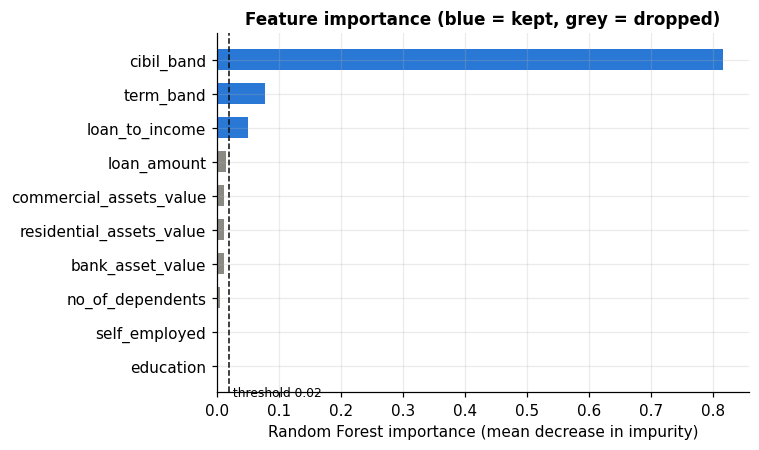

In [31]:
# G3. Model-based importance: a Random Forest (fitted on TRAIN only) ranks the remaining features
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train_s[features], y_train)
importance = pd.Series(rf.feature_importances_, index=features).sort_values()

IMP_THRESHOLD = 0.02
fig, ax = plt.subplots(figsize=(7, 0.32 * len(features) + 1))
colors = [APPROVED_C if v >= IMP_THRESHOLD else NEUTRAL_C for v in importance.values]
ax.barh(importance.index, importance.values, color=colors, height=0.6)
ax.axvline(IMP_THRESHOLD, color='#0b0b0b', linestyle='--', linewidth=1)
ax.text(IMP_THRESHOLD, -0.9, f' threshold {IMP_THRESHOLD}', fontsize=8)
ax.set_xlabel('Random Forest importance (mean decrease in impurity)')
ax.set_title('Feature importance (blue = kept, grey = dropped)')
plt.tight_layout(); plt.show()
print(importance.sort_values(ascending=False).round(4).to_string())

In [32]:
selected = importance[importance >= IMP_THRESHOLD].index.tolist()[::-1]   # most important first
dropped_imp = [c for c in features if c not in selected]
print('Kept    :', selected)
print('Dropped :', dropped_imp)

counts_g = pd.DataFrame({'step': ['Start of Stage G', 'After variance threshold', 'After correlation filter',
                                  'After model-based importance'],
                         'n_features': [n_features_before_G, n_features_before_G - len(low_var),
                                        n_features_before_G - len(low_var) - len(dropped_corr), len(selected)]})
counts_g

Kept    : ['cibil_band', 'term_band', 'loan_to_income']
Dropped : ['no_of_dependents', 'education', 'self_employed', 'loan_amount', 'residential_assets_value', 'commercial_assets_value', 'bank_asset_value']


,step,n_features
0,Start of Stage G,16
1,After variance threshold,16
2,After correlation filter,10
3,After model-based importance,3


**G3 reasoning:** the random forest measures how much each feature helps split Approved from Rejected. The credit-score information
dominates by a wide margin. The loan-term band and the loan-to-income ratio add a little. Features below the **0.02** threshold
contribute almost nothing, so we drop them. This removes noise and gives a smaller, easier-to-explain model. The weak features include the
personal attributes (`education`, `self_employed`, `no_of_dependents`) and the flat `income_band` we flagged in Stage D.

PCA: 16 features -> 9 components keep 96.4% of the variance


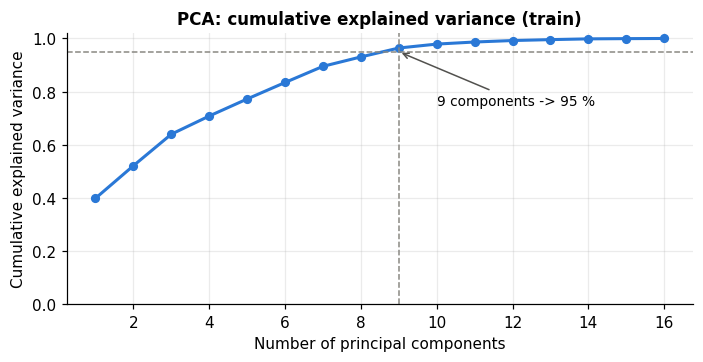

In [33]:
# G4. Feature extraction for comparison: PCA on all standardised features (fitted on TRAIN only)
pca_full = PCA().fit(X_train_s)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_pc = int(np.argmax(cum_var >= 0.95) + 1)

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(range(1, len(cum_var) + 1), cum_var, marker='o', markersize=5, linewidth=2, color=APPROVED_C)
ax.axhline(0.95, color=NEUTRAL_C, linestyle='--', linewidth=1)
ax.axvline(n_pc, color=NEUTRAL_C, linestyle='--', linewidth=1)
ax.annotate(f'{n_pc} components -> 95 %', (n_pc, 0.95), xytext=(n_pc + 1, 0.75), fontsize=9,
            arrowprops=dict(arrowstyle='->', color='#52514e'))
ax.set_xlabel('Number of principal components'); ax.set_ylabel('Cumulative explained variance')
ax.set_title('PCA: cumulative explained variance (train)'); ax.set_ylim(0, 1.02)
plt.tight_layout(); plt.show()

pca = PCA(n_components=n_pc).fit(X_train_s)
X_train_pca, X_test_pca = pca.transform(X_train_s), pca.transform(X_test_s)
print(f'PCA: {X_train_s.shape[1]} features -> {n_pc} components keep {cum_var[n_pc-1]:.1%} of the variance')

**Selection vs extraction:** PCA needs many components to keep 95 % of the variance. It also **mixes** the original columns into
abstract combinations, so we can no longer say "the model rejected this applicant because of their CIBIL score". PCA also keeps the directions
with the most *variance*, not the ones most related to the target, and the credit score is only one small direction out of 16.
Feature *selection* keeps real, explainable columns, so it is our **main pipeline**. We still train a PCA model in Stage H to compare the two approaches with evidence.

---
## Stage H: Model training and evaluation
* **Main model: Logistic Regression** on the selected, standardised features. It is a simple, interpretable baseline for binary
  classification, and each coefficient shows the direction and strength of a feature's effect.
* **For comparison:** Logistic Regression on the PCA components, and a shallow **Decision Tree** (depth 4) on the selected features.
* **Reference point:** a "model" that always predicts the majority class (Approved). Any real model must beat this.
* **Metrics:** accuracy, plus **F1-score** for the Rejected class, because the classes are imbalanced (62 : 38) and wrongly approving a bad loan is the costly mistake.
All models are trained on the training set and scored **once** on the untouched test set.

In [34]:
results = []
def evaluate(name, model, Xtr, Xte, n_feat):
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    results.append({'model': name, 'n_features': n_feat,
                    'test_accuracy': accuracy_score(y_test, pred),
                    'f1_rejected': f1_score(y_test, pred, pos_label=0),
                    'f1_approved': f1_score(y_test, pred, pos_label=1)})
    return model, pred

majority = int(y_train.mode()[0])
base_pred = np.full(len(y_test), majority)
results.append({'model': 'Baseline: always "Approved"', 'n_features': 0,
                'test_accuracy': accuracy_score(y_test, base_pred),
                'f1_rejected': f1_score(y_test, base_pred, pos_label=0, zero_division=0),
                'f1_approved': f1_score(y_test, base_pred, pos_label=1)})

logreg, pred_lr = evaluate('Logistic Regression (selected features)',
                           LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
                           X_train_s[selected], X_test_s[selected], len(selected))
evaluate('Logistic Regression (PCA components)', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
         X_train_pca, X_test_pca, n_pc)
evaluate('Decision Tree, depth 4 (selected features)',
         DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
         X_train_s[selected], X_test_s[selected], len(selected))

results_df = pd.DataFrame(results).set_index('model')
print(results_df.to_string(float_format='{:.3f}'.format))

                                            n_features  test_accuracy  f1_rejected  f1_approved
model                                                                                          
Baseline: always "Approved"                          0          0.622        0.000        0.767
Logistic Regression (selected features)              3          0.992        0.989        0.993
Logistic Regression (PCA components)                 9          0.956        0.940        0.965
Decision Tree, depth 4 (selected features)           3          0.996        0.995        0.997


Logistic Regression (selected features): classification report on the TEST set

              precision    recall  f1-score   support

Rejected (0)      0.988     0.991     0.989       323
Approved (1)      0.994     0.992     0.993       531

    accuracy                          0.992       854
   macro avg      0.991     0.992     0.991       854
weighted avg      0.992     0.992     0.992       854



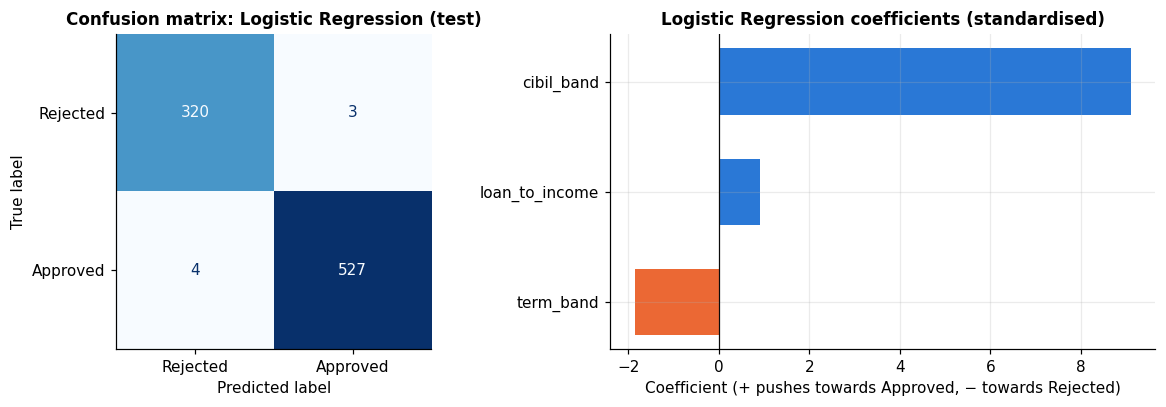

In [35]:
print('Logistic Regression (selected features): classification report on the TEST set\n')
print(classification_report(y_test, pred_lr, target_names=['Rejected (0)', 'Approved (1)'], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={'width_ratios': [1, 1.25]})
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_lr), display_labels=['Rejected', 'Approved']).plot(
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Confusion matrix: Logistic Regression (test)'); axes[0].grid(False)
axes[0].set_xlabel('Predicted label'); axes[0].set_ylabel('True label')

coef = pd.Series(logreg.coef_[0], index=selected).sort_values()
axes[1].barh(coef.index, coef.values, color=[APPROVED_C if v > 0 else REJECTED_C for v in coef.values], height=0.6)
axes[1].axvline(0, color='#0b0b0b', linewidth=0.8)
axes[1].set_title('Logistic Regression coefficients (standardised)')
axes[1].set_xlabel('Coefficient (+ pushes towards Approved, − towards Rejected)')
plt.tight_layout(); plt.show()

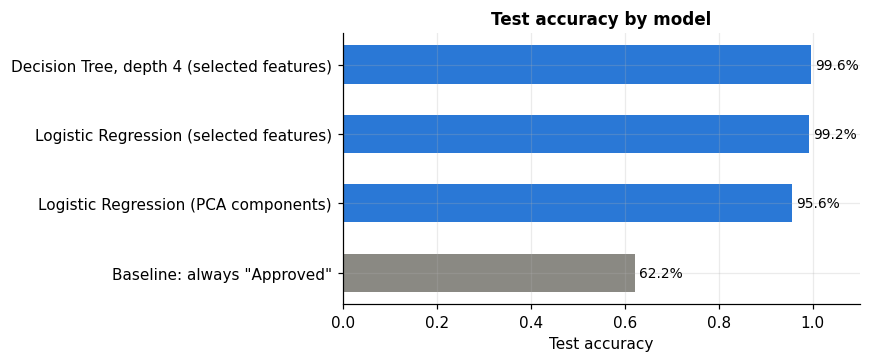

In [36]:
fig, ax = plt.subplots(figsize=(8, 3.4))
plot_df = results_df['test_accuracy'].sort_values()
bars = ax.barh(plot_df.index, plot_df.values, color=[NEUTRAL_C if 'Baseline' in i else APPROVED_C for i in plot_df.index], height=0.55)
ax.bar_label(bars, labels=[f'{v:.1%}' for v in plot_df.values], padding=3, fontsize=9)
ax.set_xlim(0, 1.1); ax.set_xlabel('Test accuracy')
ax.set_title('Test accuracy by model')
plt.tight_layout(); plt.show()

**Interpreting the results**

* All trained models clearly beat the majority-class baseline, so the preprocessed features carry real signal.
* The **Logistic Regression coefficients** match the Stage D chart: the credit-score band is by far the strongest factor, and longer
  loan terms push towards rejection. One result surprised us: a **higher loan-to-income ratio pushes slightly towards *approval***, which is the
  opposite of what a bank would expect. The effect is small, and it probably reflects how this dataset was generated rather than real lending
  logic. With a real bank's data we would investigate it before trusting it.
* The accuracy is very high (≈ 99 %). This tells us the dataset is **almost perfectly separable by the CIBIL band**. It is not a sign of leakage:
  every preprocessing step was fitted on the training set only, and the test set was scored once.
* **PCA performs worse than feature selection** with similar or more inputs. This is the evidence behind our choice in Stage G:
  PCA keeps high-*variance* directions, and those are not the ones that matter for the decision.
* The **Decision Tree** scores higher because it can learn the sharp CIBIL cut-off (~550) and interactions directly as "if score < 550 then …".
  Accuracy is not a marking criterion here. We keep Logistic Regression as the *baseline*, and the tree shows how much a
  non-linear model gains from the same preprocessed data.

---
## Summary of preprocessing decisions

| Stage | Technique | Columns | Reason |
|---|---|---|---|
| A | Whitespace stripping; drop identifier | all names and text values; `loan_id` | Leading spaces break lookups; an ID has no predictive meaning |
| Split | Stratified 80/20 split **before** any fitting | all | Prevents data leakage; keeps the 62:38 class ratio in both sets |
| B | Negative values → NaN, then **median** imputation (fitted on train) | `residential_assets_value` (28 rows) | −100,000 is impossible (a placeholder); the median is robust to the right skew |
| C | Ordinal encoding (Not Graduate < Graduate); 0/1 mapping; target 0/1; no one-hot | `education`; `self_employed`; `loan_status` | Binary/ordinal columns; there are no nominal multi-category columns |
| D | Domain bins (CIBIL bands, loan-term bands); equal-frequency quartiles (edges from train) | `cibil_score`, `loan_term`; `income_annum` | Lenders reason in score bands; approval jumps at 550; income has no natural bands |
| — | Derived ratio features | `loan_to_income`, `total_assets` | Features a loan officer would use; computed row by row, so no leakage |
| E | Square-root transform where \|skew\| > 0.75 (log1p tested and rejected); `StandardScaler` (fitted on train) | `residential_assets_value`, `commercial_assets_value`; all features | Pull in long tails without distorting the zero values; Logistic Regression and PCA need comparable scales |
| F | IQR detection; **keep** genuine high values | asset columns | Wealthy applicants are real; after the sqrt transform no IQR outliers remain |
| G | Variance threshold → correlation filter (\|r\| > 0.85) → RF importance (≥ 0.02); PCA for comparison | all features | Remove redundant and uninformative features; keep the model explainable |
| H | Logistic Regression (baseline), Decision Tree, LR + PCA | selected features | Simple, interpretable baseline; accuracy and F1 reported on the test set |

In [37]:
print(f'Features: {n_features_start} original -> {n_features_before_G} after binning/derived -> '
      f'{len(selected)} selected ({len(selected)/n_features_before_G:.0%} kept)')
print('Selected features:', selected)
print(f"Baseline Logistic Regression test accuracy: {results_df.loc['Logistic Regression (selected features)', 'test_accuracy']:.3f}")

Features: 11 original -> 16 after binning/derived -> 3 selected (19% kept)
Selected features: ['cibil_band', 'term_band', 'loan_to_income']
Baseline Logistic Regression test accuracy: 0.992


## What we learned
1. **"No missing values" was not true.** The empty-cell count was zero, but domain sense exposed 28 impossible values. Always check that values make sense, not just that cells are filled.
2. **Binning with domain knowledge paid off.** The CIBIL band turned out to be the most informative feature, because it matches how the approval decision is actually made.
3. **The order of operations matters.** Splitting first and fitting every step on the training set only keeps the test score honest.
4. **Feature selection beat PCA** for this problem: fewer, explainable columns and better scores.

*Next steps (beyond this mid-term): cross-validation to tune the model, and a check of the class threshold, since a bank may prefer to reject more borderline applications.*